# Lab 4: TensorBoard (modified)

Karuniya Premnath, IE 7374 MLOps

Based on `Labs/Tensorflow_Labs/TensorBoard/Lab1.ipynb` from raminmohammadi/MLOps.
The original trains a one-layer model on made-up data (y = 0.5x + 2 + noise) and looks at the loss in TensorBoard.

What I changed:
- Real dataset: Forest Cover Type (54 features, 7 tree classes) instead of made-up data
- Three model configs compared with 3-fold cross-validation
- The best config is picked by **CV macro F1 only**. The test set is used once, at the very end, on the chosen model
- TensorBoard: scalars, my own custom scalars, weight histograms, HParams, a confusion matrix image, and Debugger V2
- Helper functions live in `lab_utils.py` and have unit tests in `tests/` (also run by GitHub Actions)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karunprem45/ml_tensorflow_lab4/blob/main/Lab4_TensorBoard.ipynb)

Run in Google Colab: Runtime > Run all. It takes about 10 minutes.
The badge always opens the latest version of this notebook from GitHub.

## 0. Setup

In [1]:
# Get lab_utils.py and the tests from my repo (only needed in Colab)
import os, sys, subprocess
if not os.path.exists("lab_utils.py"):
    if not os.path.exists("ml_tensorflow_lab4"):
        subprocess.run(["git", "clone", "-q", "https://github.com/karunprem45/ml_tensorflow_lab4.git"], check=True)
    sys.path.insert(0, "ml_tensorflow_lab4")
    REPO_DIR = "ml_tensorflow_lab4"
else:
    REPO_DIR = "."
print("repo folder:", REPO_DIR)

repo folder: .


In [2]:
%load_ext tensorboard
!rm -rf ./logs/

In [3]:
from datetime import datetime
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorboard.plugins.hparams import api as hp
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import lab_utils as lu

keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Data

Forest Cover Type (UCI, loaded through scikit-learn): each row is a 30m x 30m patch of forest in Colorado,
described by elevation, slope, distance to water and roads, sunlight at different times of day,
wilderness area and soil type. The task is to predict which of 7 tree types covers the patch.

The full data has 581,012 rows. I take a stratified sample of 20,000 so the runs finish in a few minutes on Colab.
The classes are very unbalanced (Cottonwood/Willow is under 1%), so I use **macro F1** as the main metric,
because plain accuracy would look fine even if the rare classes were ignored.

In [4]:
X, y = lu.load_covtype(n_samples=20000)
print("X:", X.shape)
print(pd.Series(y).map(dict(enumerate(lu.CLASS_NAMES))).value_counts().to_string())

# Hold out 20% as the test set. It is not touched again until section 5.
X_train, X_test, y_train, y_test = lu.split_data(X, y, test_size=0.2)
print("\ntrain:", X_train.shape, " test:", X_test.shape)

X: (20000, 54)
Lodgepole Pine       9752
Spruce/Fir           7292
Ponderosa Pine       1231
Krummholz             706
Douglas-fir           598
Aspen                 327
Cottonwood/Willow      94

train: (16000, 54)  test: (4000, 54)


## 2. Configs and HParams setup

Three configs differ in optimizer and starting learning rate. All use the same network
(Dense 128 > Dropout 0.2 > Dense 64 > Dense 7 softmax).

In [5]:
CONFIGS = {
    "sgd_lr0.01":   ("sgd", 0.01),
    "adam_lr0.001": ("adam", 0.001),
    "adam_lr0.01":  ("adam", 0.01),
}
EPOCHS = 25
BATCH = 256
N_FOLDS = 3

HP_OPTIMIZER = hp.HParam("optimizer", hp.Discrete(["sgd", "adam"]))
HP_LR = hp.HParam("learning_rate", hp.Discrete([0.001, 0.01]))

stamp = datetime.now().strftime("%Y%m%d-%H%M%S")
base_dir = f"logs/cv/{stamp}"

with tf.summary.create_file_writer(base_dir).as_default():
    hp.hparams_config(
        hparams=[HP_OPTIMIZER, HP_LR],
        metrics=[hp.Metric("cv_macro_f1", display_name="CV macro F1"),
                 hp.Metric("cv_accuracy", display_name="CV accuracy")],
    )

## 3. Cross-validation on the training set only

For each config and each of the 3 folds:
- the scaler is fit on that fold's training part only (no leakage into the fold's validation part)
- TensorBoard logs loss, accuracy and weight histograms; my callback adds learning rate and validation macro F1
- early stopping watches the fold's validation loss

Each config's mean CV score is written to the HParams dashboard.

In [6]:
folds = lu.cv_folds(y_train, n_splits=N_FOLDS)
cv_results = []

for name, (opt_name, lr) in CONFIGS.items():
    fold_f1, fold_acc, fold_epochs = [], [], []
    for k, (tr_idx, va_idx) in enumerate(folds, start=1):
        X_tr, X_va = lu.scale(X_train[tr_idx], X_train[va_idx])
        y_tr, y_va = y_train[tr_idx], y_train[va_idx]

        logdir = f"{base_dir}/{name}/fold{k}"
        model = lu.build_model(X_tr.shape[1], len(lu.CLASS_NAMES), opt_name, lr)
        history = model.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=EPOCHS, batch_size=BATCH, verbose=0,
            callbacks=[
                keras.callbacks.TensorBoard(log_dir=logdir, histogram_freq=1),
                keras.callbacks.LearningRateScheduler(lu.lr_schedule),
                keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
                lu.make_custom_scalars_callback(logdir, X_va, y_va),
            ],
        )
        probs = model.predict(X_va, verbose=0)
        fold_f1.append(lu.macro_f1(y_va, probs))
        fold_acc.append(accuracy_score(y_va, probs.argmax(axis=1)))
        fold_epochs.append(int(np.argmin(history.history["val_loss"])) + 1)
        print(f"{name} fold {k}: macro F1 = {fold_f1[-1]:.4f}, accuracy = {fold_acc[-1]:.4f}")

    result = {
        "run": name, "optimizer": opt_name, "learning_rate": lr,
        "cv_macro_f1": float(np.mean(fold_f1)), "cv_macro_f1_std": float(np.std(fold_f1)),
        "cv_accuracy": float(np.mean(fold_acc)), "best_epochs": int(round(np.mean(fold_epochs))),
    }
    cv_results.append(result)

    # one HParams session per config, holding its mean CV scores
    with tf.summary.create_file_writer(f"{base_dir}/{name}").as_default():
        hp.hparams({HP_OPTIMIZER: opt_name, HP_LR: lr})
        tf.summary.scalar("cv_macro_f1", result["cv_macro_f1"], step=1)
        tf.summary.scalar("cv_accuracy", result["cv_accuracy"], step=1)

sgd_lr0.01 fold 1: macro F1 = 0.3595, accuracy = 0.6935


sgd_lr0.01 fold 2: macro F1 = 0.3633, accuracy = 0.6797


sgd_lr0.01 fold 3: macro F1 = 0.3297, accuracy = 0.6902


adam_lr0.001 fold 1: macro F1 = 0.5228, accuracy = 0.7495


adam_lr0.001 fold 2: macro F1 = 0.5469, accuracy = 0.7420


adam_lr0.001 fold 3: macro F1 = 0.5475, accuracy = 0.7624


adam_lr0.01 fold 1: macro F1 = 0.6134, accuracy = 0.7868


adam_lr0.01 fold 2: macro F1 = 0.6589, accuracy = 0.7934


adam_lr0.01 fold 3: macro F1 = 0.6732, accuracy = 0.7980


## 4. Pick the best config by CV score

`select_best` only looks at `cv_macro_f1`. No test numbers exist at this point.

In [7]:
cv_df = pd.DataFrame(cv_results).sort_values("cv_macro_f1", ascending=False)
display(cv_df.round(4))

best = lu.select_best(cv_results, metric="cv_macro_f1")
print(f"Best config by CV macro F1: {best['run']} "
      f"({best['cv_macro_f1']:.4f} +/- {best['cv_macro_f1_std']:.4f}), "
      f"retraining for {best['best_epochs']} epochs")

,run,optimizer,learning_rate,cv_macro_f1,cv_macro_f1_std,cv_accuracy,best_epochs
2,adam_lr0.01,adam,0.010,0.6485,0.0255,0.7928,24
1,adam_lr0.001,adam,0.001,0.5391,0.0115,0.7513,25
0,sgd_lr0.01,sgd,0.010,0.3508,0.0150,0.6878,25


Best config by CV macro F1: adam_lr0.01 (0.6485 +/- 0.0255), retraining for 24 epochs


## 5. Retrain the chosen config and test it once

The chosen config is retrained on the full training set (scaler fit on the full training set),
for the average number of epochs that worked best in CV. Then it is evaluated on the test set **once**.
The confusion matrix is logged to TensorBoard's Images tab.

Test macro F1: 0.6577
Test accuracy: 0.8067

                   precision    recall  f1-score   support

       Spruce/Fir       0.85      0.74      0.79      1458
   Lodgepole Pine       0.80      0.90      0.85      1951
   Ponderosa Pine       0.72      0.82      0.76       246
Cottonwood/Willow       0.45      0.26      0.33        19
            Aspen       0.76      0.40      0.53        65
      Douglas-fir       0.58      0.49      0.53       120
        Krummholz       0.84      0.79      0.81       141

         accuracy                           0.81      4000
        macro avg       0.72      0.63      0.66      4000
     weighted avg       0.81      0.81      0.80      4000



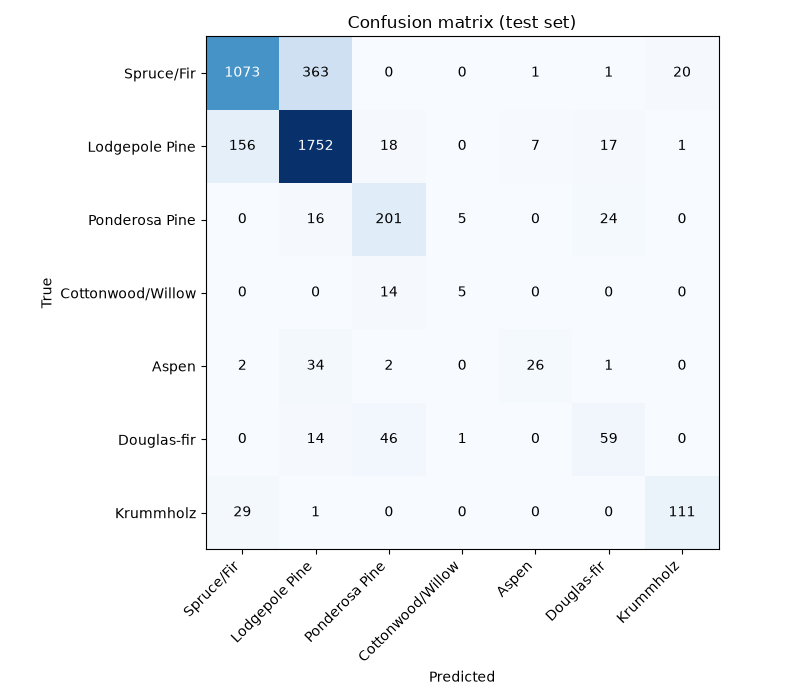

In [8]:
X_train_s, X_test_s = lu.scale(X_train, X_test)

final_dir = f"logs/final/{best['run']}"
final_model = lu.build_model(X_train_s.shape[1], len(lu.CLASS_NAMES), best["optimizer"], best["learning_rate"])
final_model.fit(
    X_train_s, y_train,
    epochs=best["best_epochs"], batch_size=BATCH, verbose=0,
    callbacks=[
        keras.callbacks.TensorBoard(log_dir=final_dir, histogram_freq=1),
        keras.callbacks.LearningRateScheduler(lu.lr_schedule),
    ],
)

test_probs = final_model.predict(X_test_s, verbose=0)
test_pred = test_probs.argmax(axis=1)
print(f"Test macro F1: {lu.macro_f1(y_test, test_probs):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, test_pred):.4f}\n")
print(classification_report(y_test, test_pred, target_names=lu.CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_test, test_pred, labels=range(len(lu.CLASS_NAMES)))
fig = lu.confusion_matrix_figure(cm, lu.CLASS_NAMES)
with tf.summary.create_file_writer(final_dir + "/images").as_default():
    tf.summary.image("confusion_matrix_test", lu.figure_to_image(fig), step=0)

from IPython.display import Image
Image(lu.figure_to_png_bytes(fig))

## 6. Debugger V2: making a model fail on purpose

The original lab turns on the debugger, but its model trains fine, so there is nothing to find.
Here I train on **unscaled** features (elevation is in the thousands) with a high SGD learning rate (0.5),
which makes the loss turn into NaN in the first epoch. Debugger V2 then shows NaN/Inf alerts.
(With 0.1 the loss only spikes and then recovers, so there is nothing for the debugger to catch.)
The debugger is only on for this cell because it slows training a lot.

In [9]:
tf.debugging.experimental.enable_dump_debug_info(
    "logs/debugger", tensor_debug_mode="FULL_HEALTH", circular_buffer_size=-1
)

bad_model = lu.build_model(X_train.shape[1], len(lu.CLASS_NAMES), "sgd", 0.5)
bad_history = bad_model.fit(X_train[:2000], y_train[:2000], epochs=3, batch_size=64, verbose=1)
print("final loss:", bad_history.history["loss"][-1])

tf.debugging.experimental.disable_dump_debug_info()

INFO:tensorflow:Enabled dumping callback in thread MainThread (dump root: logs/debugger, tensor debug mode: FULL_HEALTH)


Epoch 1/3


 1/32 ━━━━━━━━━━━━━━━━━━━━ 11s 358ms/step - accuracy: 0.0625 - loss: 434.5303

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3750 - loss: nan        


Epoch 2/3


 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3750 - loss: nan

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3720 - loss: nan


Epoch 3/3


 1/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3750 - loss: nan

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3720 - loss: nan


final loss: nan
INFO:tensorflow:Disabled dumping callback in thread MainThread (dump root: logs/debugger)


## 7. Unit tests

In [10]:
!pip -q install pytest
!python -m pytest -v {REPO_DIR}/tests

============================= test session starts ==============================
platform darwin -- Python 3.11.18, pytest-9.2.0, pluggy-1.7.0 -- python
cachedir: .pytest_cache
rootdir: .
plugins: platformdirs-4.14.5
collecting ... 

collected 11 items                                                             

tests/test_lab_utils.py::test_split_sizes_and_no_overlap PASSED          [  9%]


tests/test_lab_utils.py::test_split_is_stratified PASSED                 [ 18%]
tests/test_lab_utils.py::test_scale_fits_on_first_array_only PASSED      [ 27%]
tests/test_lab_utils.py::test_cv_folds_cover_every_row_once PASSED       [ 36%]
tests/test_lab_utils.py::test_lr_schedule PASSED                         [ 45%]
tests/test_lab_utils.py::test_macro_f1_perfect_and_wrong PASSED          [ 54%]
tests/test_lab_utils.py::test_select_best_uses_cv_not_test PASSED        [ 63%]
tests/test_lab_utils.py::test_select_best_empty_raises PASSED            [ 72%]
tests/test_lab_utils.py::test_confusion_matrix_figure_makes_png 

PASSED   [ 81%]
tests/test_lab_utils.py::test_build_model_output_shape_and_probabilities 

PASSED [ 90%]
tests/test_lab_utils.py::test_build_model_rejects_unknown_optimizer PASSED [100%]

============================== 11 passed in 2.56s ==============================


## 8. TensorBoard

- **Scalars / Time Series**: loss and accuracy for every config and fold; `learning_rate` and `val_macro_f1` under the `custom` runs
- **Graphs**: the model layers
- **Histograms / Distributions**: weights changing over epochs
- **HParams**: the three configs side by side with their CV scores (table view and parallel coordinates view)
- **Images**: test-set confusion matrix of the chosen model

Debugger V2 only reads debugger data that sits directly in `--logdir`, so it needs its own TensorBoard
pointed at `logs/debugger` (second cell below). It shows the NaN/Inf alerts from section 6.

In [ ]:
%tensorboard --logdir logs/

In [ ]:
%tensorboard --logdir logs/debugger --port 6007